<a href="https://colab.research.google.com/github/Raunaksingh2005/Bitstream/blob/main/Mock_Ai_Interview_Platfrom_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import glob

In [ ]:
path = kagglehub.dataset_download("yaswanthkumary/ai-recruitment-pipeline-dataset")

100%|██████████| 18.9M/18.9M [00:00<00:00, 214MB/s]

Extracting files...


In [ ]:
df_kaggle = pd.read_csv(glob.glob(path + "/*.csv")[0])

In [ ]:
df_kaggle["Application_Date"] = pd.date_range(end="2026-10-01", periods=len(df_kaggle), freq="12min")

In [ ]:
display(df_kaggle.head())

,ID,Name,Role,Transcript,Resume,decision,Reason_for_decision,Job_Description,Application_Date
0,jasojo159,Jason Jones,E-commerce Specialist,"Interviewer: Good morning, Jason. It's great t...",Here's a professional resume for Jason Jones:\...,reject,Lacked leadership skills for a senior position.,Be part of a passionate team at the forefront ...,2026-07-08 05:24:00
1,annma759,Ann Marshall,Game Developer,Interview Scene\n\nA conference room with a ta...,Here's a professional resume for Ann Marshall:...,select,Strong technical skills in AI and ML.,Help us build the next-generation products as ...,2026-07-08 05:36:00
2,patrmc729,Patrick Mcclain,Human Resources Specialist,Interview Setting: A conference room in a medi...,Here's a professional resume for Patrick Mccla...,reject,Insufficient system design expertise for senio...,We need a Human Resources Specialist to enhanc...,2026-07-08 05:48:00
3,patrgr422,Patricia Gray,E-commerce Specialist,Here's a simulated professional interview for ...,Here's a professional resume for Patricia Gray...,select,Impressive leadership and communication abilit...,Be part of a passionate team at the forefront ...,2026-07-08 06:00:00
4,amangr696,Amanda Gross,E-commerce Specialist,Here's the simulated interview:\n\nInterviewer...,Here's a professional resume for Amanda Gross:...,reject,Lacked leadership skills for a senior position.,We are looking for an experienced E-commerce S...,2026-07-08 06:12:00


In [ ]:
df_form = pd.read_excel("/content/google_form_recruitment_dirty.xlsx")
display(df_form.head())

,Timestamp,ID,Name,Email,Role,Transcript,Resume,decision,Reason_for_decision,Job_Description
0,2026-10-07 21:38:00,GF_10204,Niharika Malhotra,niharika.malhotra900@gmail.com,DevOps Engineer,"Interviewer: Welcome Niharika Malhotra, tell m...",Name: Niharika Malhotra | Email: niharika.malh...,select,NaN,We are hiring a DevOps Engineer. Required skil...
1,2026-10-08 19:38:00,GF_10011,Dev Dhillon,dev2410991103.becse24@chitkara.edu.in,Frontend Developer,"Interviewer: Welcome Dev Dhillon, tell me abou...",NaN,reject,Struggled with foundational concepts and syste...,We are hiring a Frontend Developer. Required s...
2,2026-11-13 19:20:00,GF_10153,Abhishek Dhillon,abhishek2410991657.becse24@chitkara.edu.in,UI/UX Designer,"Interviewer: Welcome Abhishek Dhillon, tell me...",Name: Abhishek Dhillon | Email: abhishek241099...,select,Excellent communication skills paired with str...,We are hiring a UI/UX Designer. Required skill...
3,2026-10-10 22:00:00,GF_10010,Kavya Deshmukh,kavya.deshmukh373@gmail.com,Business Analyst,"Interviewer: Welcome Kavya Deshmukh, tell me a...",Name: Kavya Deshmukh | Email: kavya.deshmukh37...,select,Strong technical alignment with role requireme...,We are hiring a Business Analyst. Required ski...
4,2026-11-06 09:52:00,GF_10234,Shanaya Tiwari,shanaya.tiwari668@gmail.com,UI/UX Designer,"Interviewer: Welcome Shanaya Tiwari, tell me a...",Name: Shanaya Tiwari | Email: shanaya.tiwari66...,Reject,Strong technical alignment with role requireme...,We are hiring a UI/UX Designer. Required skill...


In [ ]:
df_form["Application_Date"] = pd.to_datetime(df_form["Timestamp"])

In [ ]:
df_form = df_form.drop(columns=["Timestamp", "Email"])

In [ ]:
df = pd.concat([df_kaggle, df_form], ignore_index=True)

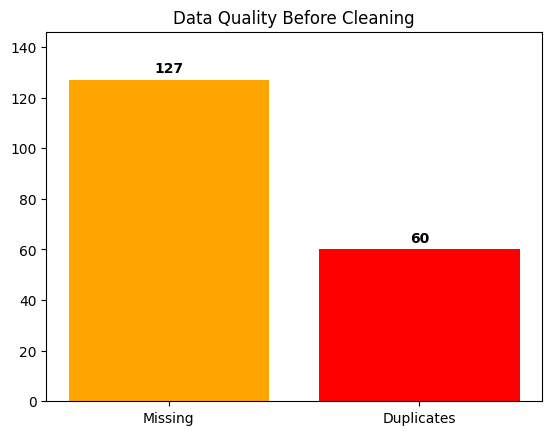

In [ ]:
before = [df.isnull().sum().sum(), df.duplicated().sum()]
bars = plt.bar(['Missing', 'Duplicates'], before, color=['orange', 'red'])
plt.bar_label(bars, padding=3, fontweight='bold')
plt.ylim(0, max(before) * 1.15)
plt.title('Data Quality Before Cleaning')
plt.show()

In [ ]:
df = df.replace(["N/A", "none", "---", "?"], np.nan)
df = df.dropna(subset=["Transcript", "Resume", "decision", "Role"])
df = df.drop_duplicates()

In [ ]:
df["Name"] = df["Name"].astype(str).str.strip().str.title()
df["Role"] = df["Role"].astype(str).str.strip().str.title()
df["decision"] = df["decision"].astype(str).str.strip().str.lower().replace({"selected": "select", "rejected": "reject"})

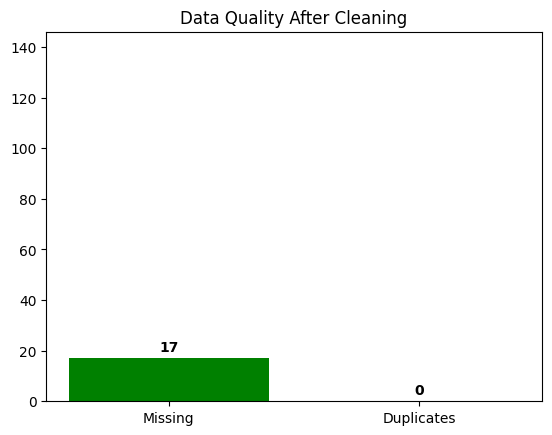

In [ ]:
after = [df.isnull().sum().sum(), df.duplicated().sum()]
bars = plt.bar(['Missing', 'Duplicates'], after, color=['green', 'blue'])
plt.bar_label(bars, padding=3, fontweight='bold')
plt.ylim(0, max(before) * 1.15)
plt.title('Data Quality After Cleaning')
plt.show()

In [ ]:
print("Cleaned Merged Shape:", df.shape)
print("Decision Counts:\n", df["decision"].value_counts())

Cleaned Merged Shape: (10334, 9)
Decision Counts:
 decision
select    5176
reject    5158
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, f_classif

In [ ]:
df["target"] = df["decision"].map({"select": 1, "reject": 0})
df["word_count"] = df["Transcript"].str.split().str.len()
df["resume_length"] = df["Resume"].str.split().str.len()
df["job_length"] = df["Job_Description"].str.split().str.len()

In [ ]:
df["word_count_scaled"] = StandardScaler().fit_transform(df[["word_count"]])
df["resume_length_scaled"] = StandardScaler().fit_transform(df[["resume_length"]])
df["job_length_scaled"] = StandardScaler().fit_transform(df[["job_length"]])
df["word_count_norm"] = MinMaxScaler().fit_transform(df[["word_count"]])

In [ ]:
def word_overlap(text, job_desc):
    t_words = set(str(text).lower().split())
    j_words = set(str(job_desc).lower().split())
    return len(t_words & j_words) / len(j_words) if j_words else 0

df["relevance_score"] = df.apply(lambda r: word_overlap(r["Transcript"] + " " + r["Resume"], r["Job_Description"]), axis=1)

In [ ]:
tfidf = TfidfVectorizer(max_features=100, stop_words="english", ngram_range=(1, 2))
X_text = tfidf.fit_transform(df["Transcript"] + " " + df["Resume"]).toarray()

selector = SelectKBest(f_classif, k=30)
X_text_best = selector.fit_transform(X_text, df["target"])

X = np.hstack([df[["word_count_scaled", "resume_length_scaled", "job_length_scaled", "relevance_score"]].values, X_text_best])
y = df["target"].values

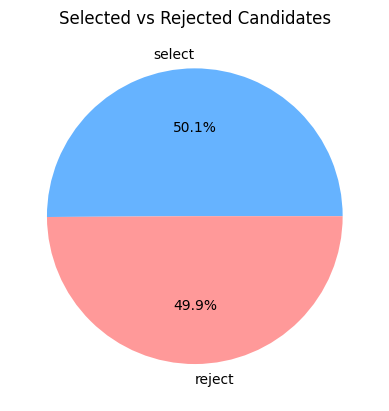

Feature Matrix X Shape: (10334, 34)


In [ ]:
df["decision"].value_counts().plot(kind="pie", autopct="%1.1f%%", colors=["#66b3ff", "#ff9999"])
plt.title("Selected vs Rejected Candidates")
plt.ylabel("")
plt.show()

print("Feature Matrix X Shape:", X.shape)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
X_reg = np.hstack([df[["word_count_scaled", "resume_length_scaled", "job_length_scaled"]].values, X_text_best[:, :5]])
y_reg = df["relevance_score"].values
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

In [ ]:
m_simple = LinearRegression().fit(Xr_tr[:, [0]], yr_tr)
p_simple = m_simple.predict(Xr_te[:, [0]])

In [ ]:
m_multi = LinearRegression().fit(Xr_tr, yr_tr)
p_multi = m_multi.predict(Xr_te)

In [ ]:
poly = PolynomialFeatures(degree=2)
m_poly = LinearRegression().fit(poly.fit_transform(Xr_tr[:, :3]), yr_tr)
p_poly = m_poly.predict(poly.transform(Xr_te[:, :3]))

r2_list = []
for name, p in [("Simple Linear", p1 := p_simple), ("Multiple Linear", p2 := p_multi), ("Polynomial (deg=2)", p3 := p_poly)]:
    mae = mean_absolute_error(yr_te, p)
    mse = mean_squared_error(yr_te, p)
    rmse = np.sqrt(mse)
    r2 = r2_score(yr_te, p)
    r2_list.append(r2)
    print(f"{name:18s} | MAE={mae:.4f} | MSE={mse:.4f} | RMSE={rmse:.4f} | R2={r2:.4f}")

Simple Linear      | MAE=0.0987 | MSE=0.0163 | RMSE=0.1277 | R2=0.0219
Multiple Linear    | MAE=0.0834 | MSE=0.0122 | RMSE=0.1105 | R2=0.2683
Polynomial (deg=2) | MAE=0.0816 | MSE=0.0117 | RMSE=0.1083 | R2=0.2971


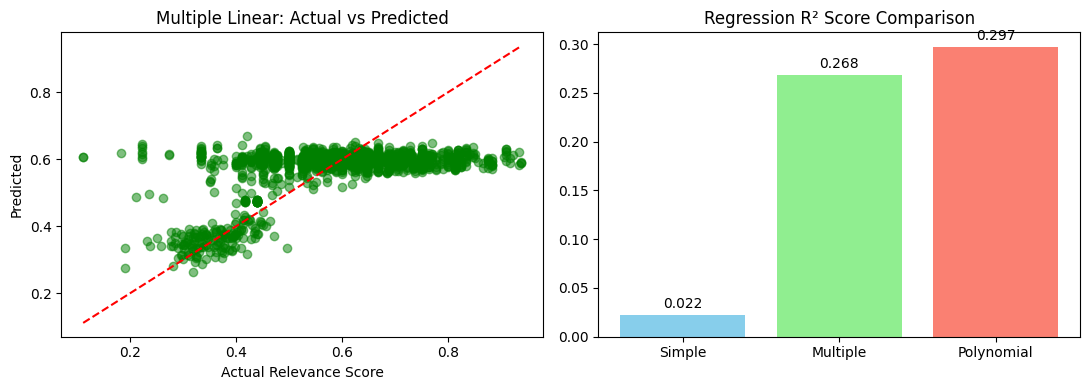

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yr_te, p_multi, alpha=0.5, color="green")
ax[0].plot([yr_te.min(), yr_te.max()], [yr_te.min(), yr_te.max()], "r--")
ax[0].set_title("Multiple Linear: Actual vs Predicted")
ax[0].set_xlabel("Actual Relevance Score")
ax[0].set_ylabel("Predicted")

bars = ax[1].bar(["Simple", "Multiple", "Polynomial"], r2_list, color=["skyblue", "lightgreen", "salmon"])
ax[1].bar_label(bars, fmt="%.3f", padding=3)
ax[1].set_title("Regression R² Score Comparison")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
models = {
    "Logistic Reg": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", random_state=42)
}

In [ ]:
accs = {}
for name, clf in models.items():
    p = clf.fit(X_train, y_train).predict(X_test)
    accs[name] = accuracy_score(y_test, p) * 100
    cv = cross_val_score(clf, X, y, cv=5).mean() * 100
    print(f"{name:14s} | Acc={accs[name]:.1f}% | Prec={precision_score(y_test,p):.2f} | Rec={recall_score(y_test,p):.2f} | F1={f1_score(y_test,p):.2f} | 5-Fold CV={cv:.1f}%")

Logistic Reg   | Acc=61.0% | Prec=0.60 | Rec=0.67 | F1=0.63 | 5-Fold CV=58.8%
KNN            | Acc=58.2% | Prec=0.58 | Rec=0.58 | F1=0.58 | 5-Fold CV=53.1%
Decision Tree  | Acc=58.7% | Prec=0.56 | Rec=0.84 | F1=0.67 | 5-Fold CV=55.5%
Random Forest  | Acc=63.8% | Prec=0.64 | Rec=0.65 | F1=0.64 | 5-Fold CV=59.0%
Naive Bayes    | Acc=60.1% | Prec=0.60 | Rec=0.60 | F1=0.60 | 5-Fold CV=54.2%
SVM            | Acc=61.9% | Prec=0.59 | Rec=0.78 | F1=0.67 | 5-Fold CV=56.3%


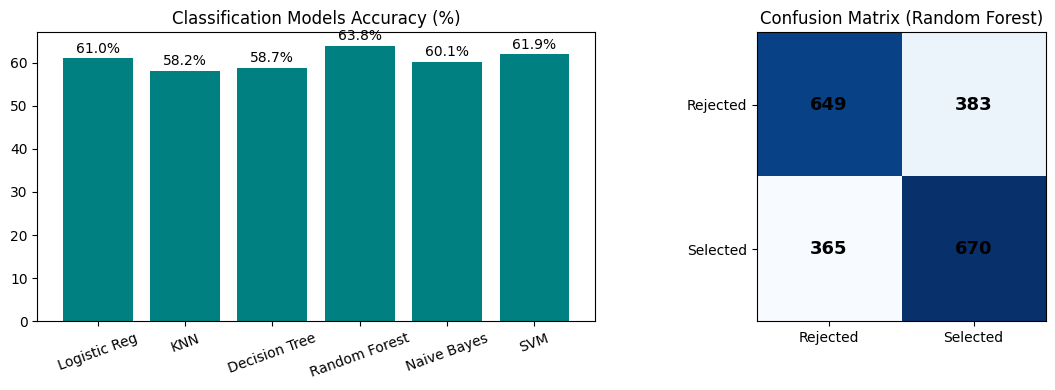

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bars = ax[0].bar(accs.keys(), accs.values(), color="teal")
ax[0].bar_label(bars, fmt="%.1f%%", padding=2)
ax[0].tick_params(axis="x", rotation=20)
ax[0].set_title("Classification Models Accuracy (%)")

best_pred = models["Random Forest"].predict(X_test)
cm = confusion_matrix(y_test, best_pred)
im = ax[1].imshow(cm, cmap="Blues")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Rejected", "Selected"])
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["Rejected", "Selected"])
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=13, fontweight="bold")
ax[1].set_title("Confusion Matrix (Random Forest)")
plt.tight_layout()
plt.show()

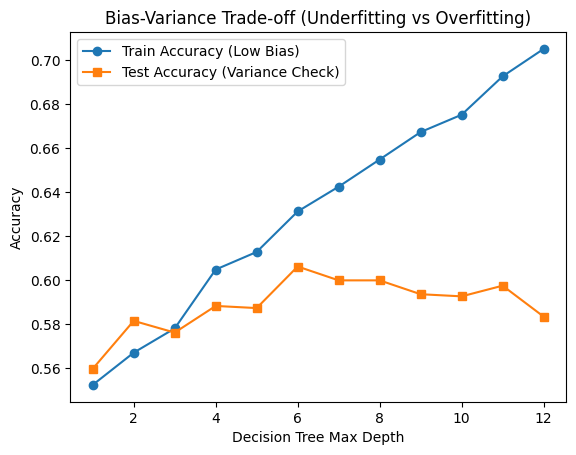

In [ ]:
depths = range(1, 13)
tr_scores = [DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train).score(X_train, y_train) for d in depths]
te_scores = [DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train).score(X_test, y_test) for d in depths]

plt.plot(depths, tr_scores, marker="o", label="Train Accuracy (Low Bias)")
plt.plot(depths, te_scores, marker="s", label="Test Accuracy (Variance Check)")
plt.xlabel("Decision Tree Max Depth")
plt.ylabel("Accuracy")
plt.title("Bias-Variance Trade-off (Underfitting vs Overfitting)")
plt.legend()
plt.show()

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings
warnings.filterwarnings("ignore")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import warnings
warnings.filterwarnings("ignore")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("PCA Explained Variance (2 Components):", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

PCA Explained Variance (2 Components): 77.98 %


In [ ]:
import warnings
warnings.filterwarnings("ignore")
km = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X)
hc = AgglomerativeClustering(n_clusters=2).fit_predict(X)
db = DBSCAN(eps=2.5, min_samples=5).fit_predict(X)

In [ ]:
import warnings
warnings.filterwarnings("ignore")
print(f"Silhouette Scores -> K-Means: {silhouette_score(X, km):.3f} | Hierarchical: {silhouette_score(X, hc):.3f}")

Silhouette Scores -> K-Means: 0.644 | Hierarchical: 0.644


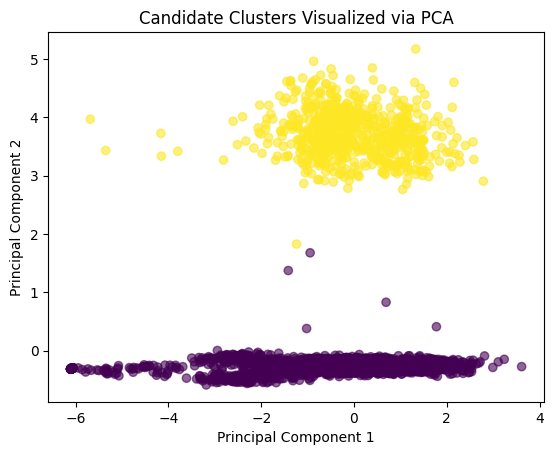

In [ ]:
import warnings
warnings.filterwarnings("ignore")
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=km, cmap="viridis", alpha=0.6)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Candidate Clusters Visualized via PCA")
plt.show()

In [ ]:
import warnings
warnings.filterwarnings("ignore")
top_terms = tfidf.get_feature_names_out()[selector.get_support()][:10]
basket = pd.DataFrame(X_text_best[:, :10] > 0, columns=top_terms)
basket["Selected"] = y == 1

In [ ]:
import warnings
warnings.filterwarnings("ignore")
freq_ap = apriori(basket, min_support=0.1, use_colnames=True)
freq_fp = fpgrowth(basket, min_support=0.1, use_colnames=True)
rules = association_rules(freq_fp, metric="confidence", min_threshold=0.5)
print("\nTop Association Rules (FP-Growth):")
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(4))


Top Association Rules (FP-Growth):
    antecedents   consequents   support  confidence      lift
0       (great)  (experience)  0.953551    0.999696  1.000180
1  (experience)       (great)  0.953551    0.954013  1.000180
2        (good)  (experience)  0.858525    0.999437  0.999921
3  (experience)        (good)  0.858525    0.858941  0.999921


In [ ]:
import warnings
warnings.filterwarnings("ignore")
sim = cosine_similarity(X[[0]], X)[0]
top3 = sim.argsort()[::-1][1:4]
print("\nRecommended Top 3 Similar Candidates for Candidate #0:", df.iloc[top3][["Name", "Role", "decision"]].to_dict("records"))


Recommended Top 3 Similar Candidates for Candidate #0: [{'Name': 'Jonathan Robinson', 'Role': 'E-Commerce Specialist', 'decision': 'select'}, {'Name': 'Michael Evans', 'Role': 'E-Commerce Specialist', 'decision': 'select'}, {'Name': 'William Donaldson', 'Role': 'E-Commerce Specialist', 'decision': 'reject'}]


In [ ]:
Q = np.zeros((3, 2))
rewards = np.array([[1, 3], [2, 5], [4, 2]])
alpha, gamma = 0.5, 0.9

for _ in range(100):
    s = np.random.randint(0, 3)
    a = np.random.randint(0, 2)
    ns = min(2, s + a)
    Q[s, a] += alpha * (rewards[s, a] + gamma * np.max(Q[ns]) - Q[s, a])

q_table = pd.DataFrame(Q, index=["Easy State", "Medium State", "Hard State"], columns=["Stay", "Level Up"]).round(2)
print("=== REINFORCEMENT LEARNING: LEARNED Q-TABLE ===")
print(q_table)


=== REINFORCEMENT LEARNING: LEARNED Q-TABLE ===
               Stay  Level Up
Easy State    21.64     23.08
Medium State  22.06     22.33
Hard State    24.11     21.70


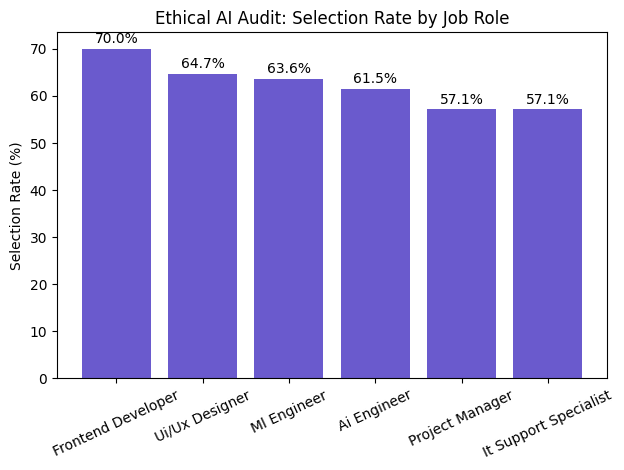

In [ ]:
fairness = df.groupby("Role")["target"].mean().sort_values(ascending=False).head(6) * 100
bars = plt.bar(fairness.index, fairness.values, color="slateblue")
plt.bar_label(bars, fmt="%.1f%%", padding=2)
plt.xticks(rotation=25)
plt.ylabel("Selection Rate (%)")
plt.title("Ethical AI Audit: Selection Rate by Job Role")
plt.tight_layout()
plt.show()

## Reinforcement Learning, Ethical Considerations & Future Trends

* **Reinforcement Learning (RL) Process:** An **agent** observes a **state ($S_t$)** from the **environment**, chooses an **action ($A_t$)**, and receives a **reward ($R_t$)** to learn an optimal policy ($Q(s,a)$) through trial and error.
  * **Robotics:** Motion planning, robotic grasping, and warehouse navigation.
  * **Gaming:** Game-playing agents (AlphaGo, Chess, Atari) mastering multi-step strategy.
  * **Autonomous Vehicles:** Real-time lane keeping, path planning, and collision avoidance.
* **Ethical Considerations in AI Recruitment:**
  * **Fairness & Bias Mitigation:** Auditing selection rates across roles and demographics to prevent historical hiring bias.
  * **Explainability (XAI):** Providing clear `Reason_for_decision` feedback instead of opaque black-box rejections.
  * **Data Privacy:** Anonymizing personal candidate PII (emails, names) during model training.
* **Future Trends in AI & ML:** Multimodal evaluation (combining text, audio, and code), Federated Learning for privacy-preserving training, and Agentic AI workflows.